# Experiment 8: Two-Layer Neural Network with Backpropagation

A two-layer network adds a hidden layer to solve nonlinear separation. We train a small NumPy network on two-moons data, code the chain-rule gradients, check one derivative numerically and plot the learned decision boundary.

**Tools:** NumPy, Scikit-learn, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Initialise input–hidden–output weights.  2. Write a sigmoid forward pass.  3. Implement backpropagation using the chain rule.  4. Train with gradient descent and plot loss.  5. Plot the decision boundary and verify one weight gradient by finite differences.

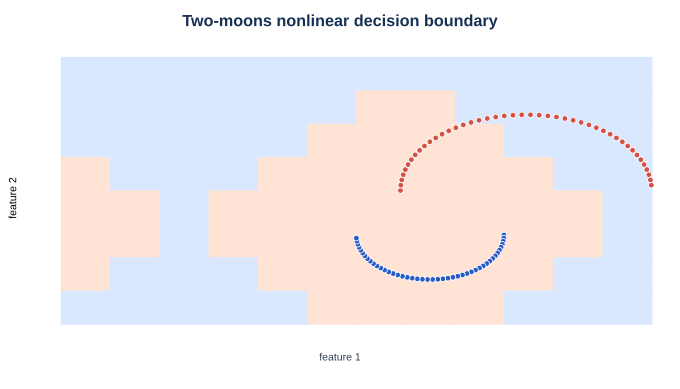

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(8)
X, y = make_moons(n_samples=300, noise=.16, random_state=8)
X = (X - X.mean(axis=0)) / X.std(axis=0)
Y = y[:, None].astype(float)
Xtr, Xte, Ytr, Yte = train_test_split(X, Y, test_size=.25, random_state=8, stratify=y)
W1 = rng.normal(0, .5, (2, 12)); b1 = np.zeros((1,12))
W2 = rng.normal(0, .5, (12, 1)); b2 = np.zeros((1,1))
sigmoid = lambda z: 1/(1+np.exp(-np.clip(z, -30, 30)))
losses = []
for epoch in range(2500):
    z1 = Xtr @ W1 + b1; a1 = sigmoid(z1)
    z2 = a1 @ W2 + b2; p = sigmoid(z2)
    loss = -np.mean(Ytr*np.log(p+1e-8) + (1-Ytr)*np.log(1-p+1e-8))
    dz2 = (p-Ytr)/len(Xtr)
    dW2 = a1.T @ dz2; db2 = dz2.sum(axis=0, keepdims=True)
    dz1 = (dz2 @ W2.T) * a1 * (1-a1)
    dW1 = Xtr.T @ dz1; db1 = dz1.sum(axis=0, keepdims=True)
    W1 -= .7*dW1; b1 -= .7*db1; W2 -= .7*dW2; b2 -= .7*db2
    if epoch % 25 == 0: losses.append(loss)
def predict_prob(A):
    return sigmoid(sigmoid(A @ W1+b1) @ W2+b2)
print("Test accuracy:", np.mean((predict_prob(Xte) >= .5) == Yte))
plt.plot(np.arange(len(losses))*25, losses)
plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy"); plt.title("Backpropagation training loss"); plt.grid(alpha=.2); plt.show()

# Recompute the analytic gradient at the current parameters, then compare to finite differences.
z1=Xtr@W1+b1; a1=sigmoid(z1); p=sigmoid(a1@W2+b2)
dz2=(p-Ytr)/len(Xtr); dz1=(dz2@W2.T)*a1*(1-a1); dW1_current=Xtr.T@dz1
def batch_loss():
    q = predict_prob(Xtr)
    return -np.mean(Ytr*np.log(q+1e-8)+(1-Ytr)*np.log(1-q+1e-8))
eps = 1e-5
analytic = dW1_current[0,0]
saved = W1[0,0]; W1[0,0] = saved + eps; plus = batch_loss()
W1[0,0] = saved - eps; minus = batch_loss(); W1[0,0] = saved
print(f"Gradient check W1[0,0]: analytic={analytic:.6g}, numeric={(plus-minus)/(2*eps):.6g}")

xx, yy = np.meshgrid(np.linspace(X[:,0].min()-1, X[:,0].max()+1, 220),
                     np.linspace(X[:,1].min()-1, X[:,1].max()+1, 220))
grid = np.c_[xx.ravel(), yy.ravel()]
plt.contourf(xx, yy, predict_prob(grid).reshape(xx.shape), levels=[0,.5,1], alpha=.25, cmap="coolwarm")
plt.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", edgecolor="k", s=20)
plt.title("Two-layer network decision boundary"); plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.tight_layout(); plt.show()